# Tugas Kelompok Sistem Rekomendasi
## Prediksi Rating dan Rekomendasi Item dengan User-Based CF, Item-Based CF, dan Matrix Factorization

| | |
|---|---|
| Kelompok | 5 |
| Anggota | Naufal Rafif Hidayat - 103012300403<br>Muhammad Alivio Putra - 103012300098<br>Akbar Jundi Pradita - 103012300081<br>Raffa Anung El Haqqi - 103012300163<br>Naufal Thafhan - 103012300284 |
| Mata Kuliah | Sistem Rekomendasi |
| Dataset | MovieLens 100K (GroupLens Research) |

### Tujuan

1. Melakukan prediksi rating dan rekomendasi item menggunakan tiga metode:
   *user-based collaborative filtering*, *item-based collaborative filtering*, dan *matrix factorization*.
2. Menguji ketiga metode dengan metrik MAE, MSE, RMSE, NMSE, dan NDCG.

### Daftar Isi

1. Persiapan library
2. Dataset
3. Eksplorasi data
4. Pembagian data latih dan data uji
5. Fungsi metrik evaluasi
6. User-Based Collaborative Filtering
7. Item-Based Collaborative Filtering
8. Matrix Factorization (Stochastic Gradient Descent)
9. Contoh rekomendasi Top-10
10. Perbandingan ketiga metode
11. Eksperimen parameter
12. Validasi silang 5-fold
13. Analisis dan kesimpulan

## 1. Persiapan Library

Library yang digunakan:

- `numpy` dan `pandas` untuk pengolahan data dan operasi matriks
- `scikit-learn` untuk `cosine_similarity` dan `train_test_split`
- `matplotlib` untuk visualisasi

Seed acak ditetapkan agar hasil dapat direproduksi.

In [1]:
import os
import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
np.random.seed(SEED)

DATA_DIR = "data"
ASSET_DIR = "assets"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(ASSET_DIR, exist_ok=True)

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"User-Based CF": "#2563eb", "Item-Based CF": "#16a34a", "Matrix Factorization": "#dc2626"}

## 2. Dataset

Dataset yang digunakan adalah MovieLens 100K dari GroupLens Research, University of Minnesota (Harper dan Konstan, 2015).
Dataset ini berisi riwayat pemberian rating (*user history*) dari user terhadap film:

- 100.000 rating dengan skala 1 sampai 5 (rating eksplisit)
- 943 user, setiap user minimal memberi 20 rating
- 1.682 film

File yang dipakai:

| File | Isi |
|---|---|
| `u.data` | `user_id`, `item_id`, `rating`, `timestamp` (dipisah tab) |
| `u.item` | informasi film: `item_id`, judul, tanggal rilis, genre |
| `u1.base` ... `u5.test` | lima pasang pembagian data latih/uji resmi untuk validasi silang 5-fold |

Sel berikut otomatis mengunduh dataset jika belum tersedia, sehingga notebook juga bisa langsung dijalankan di Google Colab.

In [2]:
DATA_URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
ZIP_PATH = os.path.join(DATA_DIR, "ml-100k.zip")
ML_DIR = os.path.join(DATA_DIR, "ml-100k")

def download_dataset():
    try:
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    except Exception:
        # beberapa komputer Windows tidak memiliki sertifikat root yang lengkap
        import ssl, shutil, certifi
        ctx = ssl.create_default_context(cafile=certifi.where())
        with urllib.request.urlopen(DATA_URL, context=ctx) as r, open(ZIP_PATH, "wb") as f:
            shutil.copyfileobj(r, f)

if not os.path.exists(os.path.join(ML_DIR, "u.data")):
    if not os.path.exists(ZIP_PATH):
        print("Mengunduh dataset ...")
        download_dataset()
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

print("File dataset:", sorted(os.listdir(ML_DIR)))

File dataset: ['README', 'allbut.pl', 'mku.sh', 'u.data', 'u.genre', 'u.info', 'u.item', 'u.occupation', 'u.user', 'u1.base', 'u1.test', 'u2.base', 'u2.test', 'u3.base', 'u3.test', 'u4.base', 'u4.test', 'u5.base', 'u5.test', 'ua.base', 'ua.test', 'ub.base', 'ub.test']


In [3]:
ratings = pd.read_csv(os.path.join(ML_DIR, "u.data"), sep="\t",
                      names=["user_id", "item_id", "rating", "timestamp"])

genre_cols = ["unknown", "Action", "Adventure", "Animation", "Children", "Comedy", "Crime",
              "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery",
              "Romance", "Sci-Fi", "Thriller", "War", "Western"]
items = pd.read_csv(os.path.join(ML_DIR, "u.item"), sep="|", encoding="latin-1", header=None,
                    names=["item_id", "title", "release_date", "video_release", "url"] + genre_cols)
titles = items.set_index("item_id")["title"]

ratings.head()

,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [4]:
n_users = ratings["user_id"].max()
n_items = ratings["item_id"].max()
n_ratings = len(ratings)
R_MIN, R_MAX = ratings["rating"].min(), ratings["rating"].max()
sparsity = 1 - n_ratings / (n_users * n_items)

print(f"Jumlah rating    : {n_ratings:,}")
print(f"Jumlah user  : {n_users:,}")
print(f"Jumlah item/film : {n_items:,}")
print(f"Skala rating     : {R_MIN} - {R_MAX}")
print(f"Rata-rata rating : {ratings['rating'].mean():.4f}")
print(f"Sparsity matriks : {sparsity:.2%} sel kosong")

Jumlah rating    : 100,000
Jumlah user  : 943
Jumlah item/film : 1,682
Skala rating     : 1 - 5
Rata-rata rating : 3.5299
Sparsity matriks : 93.70% sel kosong


## 3. Eksplorasi Data

Eksplorasi dilakukan untuk memahami karakteristik data sebelum membangun model:
distribusi nilai rating, jumlah rating per user, dan jumlah rating per film.

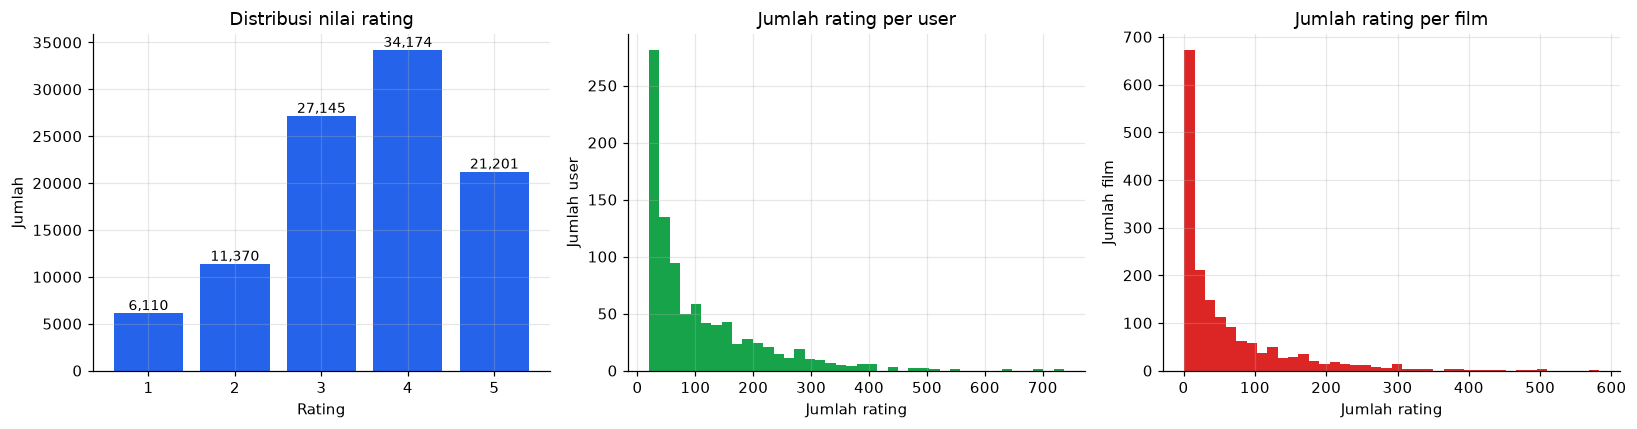

Rating per user: min=20, median=65, max=737
Rating per film    : min=1, median=27, max=583
Film dengan < 5 rating: 333 film


In [5]:
per_user = ratings.groupby("user_id").size()
per_item = ratings.groupby("item_id").size()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
counts = ratings["rating"].value_counts().sort_index()
ax[0].bar(counts.index, counts.values, color="#2563eb")
for x, y in zip(counts.index, counts.values):
    ax[0].text(x, y, f"{y:,}", ha="center", va="bottom", fontsize=9)
ax[0].set(title="Distribusi nilai rating", xlabel="Rating", ylabel="Jumlah")

ax[1].hist(per_user, bins=40, color="#16a34a")
ax[1].set(title="Jumlah rating per user", xlabel="Jumlah rating", ylabel="Jumlah user")

ax[2].hist(per_item, bins=40, color="#dc2626")
ax[2].set(title="Jumlah rating per film", xlabel="Jumlah rating", ylabel="Jumlah film")
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "eda_distribusi.png"), bbox_inches="tight")
plt.show()

print(f"Rating per user: min={per_user.min()}, median={per_user.median():.0f}, max={per_user.max()}")
print(f"Rating per film    : min={per_item.min()}, median={per_item.median():.0f}, max={per_item.max()}")
print(f"Film dengan < 5 rating: {(per_item < 5).sum()} film")

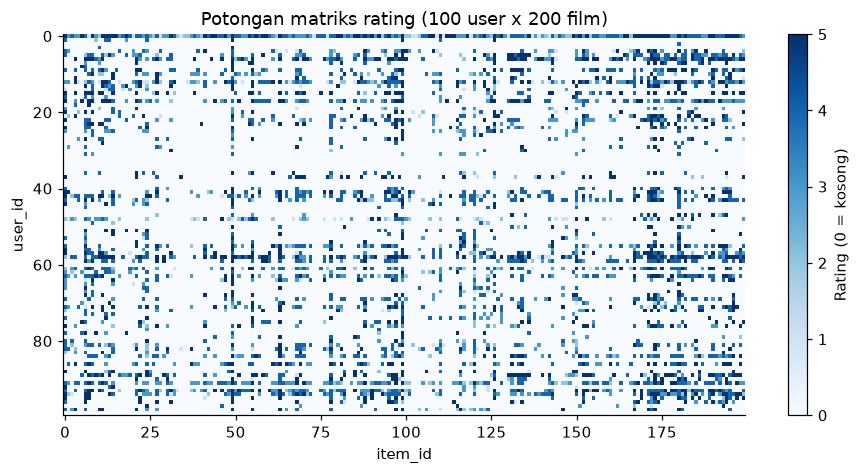

In [6]:
# Visualisasi sparsity: potongan 100 user x 200 film pertama
sample = np.zeros((100, 200))
sub = ratings[(ratings.user_id <= 100) & (ratings.item_id <= 200)]
sample[sub.user_id - 1, sub.item_id - 1] = sub.rating

plt.figure(figsize=(10, 4.5))
plt.imshow(sample, aspect="auto", cmap="Blues", interpolation="nearest")
plt.colorbar(label="Rating (0 = kosong)")
plt.title("Potongan matriks rating (100 user x 200 film)")
plt.xlabel("item_id"); plt.ylabel("user_id"); plt.grid(False)
plt.savefig(os.path.join(ASSET_DIR, "eda_sparsity.png"), bbox_inches="tight")
plt.show()

Pengamatan:

- Rating didominasi nilai 3 dan 4, sehingga rata-rata rating sekitar 3,5.
- Distribusi jumlah rating per user dan per film sangat miring (*long tail*): sebagian kecil film sangat populer, sedangkan banyak film hanya mendapat sedikit rating.
- Sekitar 93,7% sel matriks kosong. Kondisi ini disebut *sparsity problem*: dua user sering hanya memiliki sedikit item yang sama-sama dirating.

## 4. Pembagian Data Latih dan Data Uji

Sebagian rating disembunyikan sebagai data uji (*data masking*).
Model hanya dilatih dengan data latih, lalu diminta memprediksi rating yang disembunyikan.

- Data latih: 80% rating
- Data uji: 20% rating
- `random_state = 42` agar ketiga metode diuji pada pembagian yang sama persis, sehingga perbandingannya adil.

Data latih kemudian diubah menjadi matriks rating $R$ berukuran user x item, dengan nilai 0 untuk rating yang tidak diketahui.

In [7]:
train_df, test_df = train_test_split(ratings, test_size=0.2, random_state=SEED)

def build_matrix(df):
    # Membentuk matriks rating user x item (0 = belum dirating)
    R = np.zeros((n_users, n_items))
    R[df["user_id"].values - 1, df["item_id"].values - 1] = df["rating"].values
    return R

R_train = build_matrix(train_df)

print(f"Data latih : {len(train_df):,} rating")
print(f"Data uji   : {len(test_df):,} rating")
print(f"Ukuran matriks R_train : {R_train.shape}")
print("User di data uji yang tidak ada di data latih:",
      len(set(test_df.user_id) - set(train_df.user_id)))
print("Item di data uji yang tidak ada di data latih    :",
      len(set(test_df.item_id) - set(train_df.item_id)))

Data latih : 80,000 rating
Data uji   : 20,000 rating
Ukuran matriks R_train : (943, 1682)
User di data uji yang tidak ada di data latih: 0
Item di data uji yang tidak ada di data latih    : 29


Beberapa item pada data uji tidak pernah muncul di data latih (*cold-start item*).
Untuk kasus seperti ini, ketiga metode memakai nilai cadangan (*fallback* atau *default back-off*), yaitu rata-rata rating user.

## 5. Fungsi Metrik Evaluasi

Metrik dibagi menjadi dua kelompok, yaitu metrik akurasi prediksi rating dan metrik kualitas urutan rekomendasi (Baizal dan Wibowo).

Metrik akurasi prediksi rating dihitung pada seluruh pasangan user-item di data uji $T$:

$$MAE = \frac{\sum_{(u,i) \in T} |\hat{r}_{u,i} - r_{u,i}|}{|T|} \qquad
MSE = \frac{\sum_{(u,i) \in T} (\hat{r}_{u,i} - r_{u,i})^2}{|T|}$$

$$RMSE = \sqrt{MSE} \qquad NMSE = \frac{MSE}{r_{max} - r_{min}}$$

dengan $r_{max} = 5$ dan $r_{min} = 1$ adalah rating maksimum dan minimum pada dataset.

Metrik kualitas urutan rekomendasi (Top-N) menggunakan NDCG (Järvelin dan Kekäläinen, 2002):

$$DCG_l = \sum_{i=1}^{l} \frac{rel_i}{\log_2(i+1)} \qquad NDCG_l = \frac{DCG_l}{IDCG_l}$$

$IDCG_l$ adalah DCG dari urutan ideal (item diurutkan dari relevansi tertinggi).

Cara penerapan NDCG pada data rating: untuk setiap user, item-item miliknya di data uji diurutkan berdasarkan rating prediksi,
lalu relevansi setiap posisi diambil dari rating asli. NDCG dihitung sampai posisi $l = 10$ (NDCG@10), kemudian dirata-rata untuk semua user.
Dua variasi relevansi dihitung:

- NDCG@10 (graded): $rel_i$ = rating asli (1 sampai 5)
- NDCG@10 (biner): $rel_i = 1$ jika rating asli $\geq 4$, selain itu 0

*Catatan:* sebagian literatur menggunakan *gain* $2^{rel_i} - 1$. Notebook ini menggunakan $rel_i$ secara langsung untuk DCG maupun IDCG.

In [8]:
def mae(y_true, y_pred):
    return np.mean(np.abs(y_pred - y_true))

def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def nmse(y_true, y_pred, r_max=R_MAX, r_min=R_MIN):
    return mse(y_true, y_pred) / (r_max - r_min)

def dcg(relevances):
    rel = np.asarray(relevances, dtype=float)
    positions = np.arange(1, len(rel) + 1)
    return np.sum(rel / np.log2(positions + 1))

def ndcg_at_k(test, P, k=10, binary=False):
    # test: DataFrame data uji, P: matriks prediksi rating (user x item)
    scores = []
    for u, group in test.groupby("user_id"):
        item_idx = group["item_id"].values - 1
        actual = group["rating"].values.astype(float)
        rel = (actual >= 4).astype(float) if binary else actual
        predicted = P[u - 1, item_idx]
        order = np.argsort(-predicted, kind="stable")[:k]  # urutan menurut prediksi
        ideal = np.sort(rel)[::-1][:k]                       # urutan ideal
        idcg = dcg(ideal)
        if idcg > 0:
            scores.append(dcg(rel[order]) / idcg)
    return np.mean(scores)

def evaluate(name, P, test=None):
    test = test_df if test is None else test
    y_true = test["rating"].values.astype(float)
    y_pred = P[test["user_id"].values - 1, test["item_id"].values - 1]
    return {"Metode": name,
            "MAE": mae(y_true, y_pred), "MSE": mse(y_true, y_pred),
            "RMSE": rmse(y_true, y_pred), "NMSE": nmse(y_true, y_pred),
            "NDCG@10": ndcg_at_k(test, P, 10),
            "NDCG@10 (biner)": ndcg_at_k(test, P, 10, binary=True)}

### Pengujian fungsi metrik

Fungsi metrik diuji dengan contoh perhitungan yang hasilnya sudah diketahui:

1. NDCG dengan urutan relevansi hasil sistem $[3, 2, 3, 0, 1, 2]$ dan urutan ideal $[3, 3, 2, 2, 1, 0]$.
   Nilai acuan: $DCG_6 = 6{,}861$, $IDCG_6 = 7{,}141$, $NDCG_6 = 0{,}961$.
2. MAE dengan rating asli $[3, 4, 4, 5]$ dan prediksi $[5{,}0;\ 3{,}5;\ 2{,}0;\ 2{,}5]$. Nilai acuan: $MAE = 1{,}75$.

In [9]:
dcg6, idcg6 = dcg([3, 2, 3, 0, 1, 2]), dcg([3, 3, 2, 2, 1, 0])
print(f"DCG_6  = {dcg6:.3f}  (nilai acuan: 6.861)")
print(f"IDCG_6 = {idcg6:.3f}  (nilai acuan: 7.141)")
print(f"NDCG_6 = {dcg6 / idcg6:.3f}  (nilai acuan: 0.961)")

y_true_ex = np.array([3, 4, 4, 5]); y_pred_ex = np.array([5.0, 3.5, 2.0, 2.5])
print(f"MAE contoh = {mae(y_true_ex, y_pred_ex):.2f}  (nilai acuan: 1.75)")
print(f"MSE = {mse(y_true_ex, y_pred_ex):.4f}, RMSE = {rmse(y_true_ex, y_pred_ex):.4f}, "
      f"NMSE = {nmse(y_true_ex, y_pred_ex):.4f}")

DCG_6  = 6.861  (nilai acuan: 6.861)
IDCG_6 = 7.141  (nilai acuan: 7.141)
NDCG_6 = 0.961  (nilai acuan: 0.961)
MAE contoh = 1.75  (nilai acuan: 1.75)
MSE = 3.6250, RMSE = 1.9039, NMSE = 0.9062


## 6. User-Based Collaborative Filtering

User-based CF berangkat dari asumsi bahwa user yang memiliki selera serupa di masa lalu akan memiliki selera serupa di masa depan (Jannach dkk., 2010).
Untuk memprediksi rating user aktif $a$ terhadap item $p$, dicari user lain (tetangga) yang mirip dengan $a$ dan sudah merating $p$.

Langkah-langkah:

1. Hitung rata-rata rating setiap user $\bar{r}_a$.
2. Hitung kemiripan antar user dengan Pearson correlation:
$$sim(a,b) = \frac{\sum_{p \in P}(r_{a,p} - \bar{r}_a)(r_{b,p} - \bar{r}_b)}{\sqrt{\sum_{p \in P}(r_{a,p} - \bar{r}_a)^2}\sqrt{\sum_{p \in P}(r_{b,p} - \bar{r}_b)^2}}$$
3. Pilih tetangga (*neighborhood selection*): ambil $k$ user paling mirip yang sudah merating item $p$ dan memiliki similarity positif.
4. Hitung prediksi rating:
$$pred(a,p) = \bar{r}_a + \frac{\sum_{b \in N} sim(a,b)\,(r_{b,p} - \bar{r}_b)}{\sum_{b \in N} sim(a,b)}$$
5. Jika tidak ada tetangga yang memenuhi syarat, prediksi = $\bar{r}_a$ (*fallback*).

### 6.1 Verifikasi dengan contoh kasus Alice

Sebelum diterapkan ke dataset besar, perhitungan diuji pada contoh kasus Alice dari Jannach dkk. (2010).
Nilai acuan: $sim(Alice, User1) = 0{,}85$, $sim(Alice, User2) = 0{,}70$ (nilai tepatnya 0,7071, sehingga tampil 0,71 jika dibulatkan), dan prediksi rating Alice untuk Item5 = $4{,}87$.

In [10]:
alice = pd.DataFrame(
    [[5, 3, 4, 4, np.nan],
     [3, 1, 2, 3, 3],
     [4, 3, 4, 3, 5],
     [3, 3, 1, 5, 4],
     [1, 5, 5, 2, 1]],
    index=["Alice", "User1", "User2", "User3", "User4"],
    columns=["Item1", "Item2", "Item3", "Item4", "Item5"])

def pearson(a, b):
    # Pearson correlation pada item yang dirating oleh kedua user
    mask = ~np.isnan(a) & ~np.isnan(b)
    da, db = a[mask] - a[mask].mean(), b[mask] - b[mask].mean()
    return (da @ db) / (np.sqrt(da @ da) * np.sqrt(db @ db))

target = alice.loc["Alice"].values
sims = pd.Series({u: pearson(target, alice.loc[u].values) for u in alice.index[1:]})
print("Similarity Alice dengan user lain:")
print(sims.round(2).to_string())

# Prediksi dengan k = 2 tetangga terdekat (User1 dan User2)
neighbors = sims.sort_values(ascending=False).index[:2]
r_alice = np.nanmean(target)
num = sum(sims[b] * (alice.loc[b, "Item5"] - alice.loc[b].mean()) for b in neighbors)
den = sum(sims[b] for b in neighbors)
print(f"\nTetangga terpilih: {list(neighbors)}")
print(f"Prediksi rating Alice untuk Item5 = {r_alice + num / den:.2f}  (nilai acuan: 4.87)")

Similarity Alice dengan user lain:
User1    0.85
User2    0.71
User3    0.00
User4   -0.79

Tetangga terpilih: ['User1', 'User2']
Prediksi rating Alice untuk Item5 = 4.87  (nilai acuan: 4.87)


### 6.2 Implementasi untuk dataset MovieLens

Pada dataset besar, perhitungan Pearson untuk setiap pasangan user satu per satu terlalu lambat.
Karena itu perhitungan dilakukan dalam bentuk operasi matriks:

1. Buat matriks baru berisi selisih rating dengan rata-rata user (*mean-centering*). Sel kosong bernilai 0.
2. Hitung cosine similarity antarbaris matriks tersebut dengan `sklearn.metrics.pairwise.cosine_similarity`.
   Cosine similarity pada data yang sudah dikurangi rata-ratanya setara dengan Pearson correlation.
3. Untuk setiap user, tetangga diurutkan dari yang paling mirip, lalu untuk setiap item diambil $k$ tetangga pertama yang sudah merating item tersebut.

Hasilnya adalah matriks prediksi rating lengkap (943 x 1.682) yang dipakai untuk evaluasi dan rekomendasi.
Nilai $k = 30$ dipilih karena untuk dataset MovieLens, jumlah tetangga 20 sampai 50 umumnya sudah memadai (Jannach dkk., 2010).

In [11]:
def user_means(R):
    mask = R > 0
    counts = mask.sum(axis=1)
    global_mean = R[mask].mean()
    return np.where(counts > 0, R.sum(axis=1) / np.maximum(counts, 1), global_mean)

def user_similarity(R):
    # Langkah 1-2: mean-centering lalu cosine similarity antar user
    mask = R > 0
    mu = user_means(R)
    centered = (R - mu[:, None]) * mask
    S = cosine_similarity(centered)
    np.fill_diagonal(S, 0)          # user tidak dihitung sebagai tetangga dirinya sendiri
    return S, centered, mu

def predict_user_based(R, k=30, S=None):
    mask = R > 0
    S_, centered, mu = user_similarity(R)
    S = S_ if S is None else S
    P = np.zeros_like(R, dtype=float)
    for a in range(R.shape[0]):
        order = np.argsort(-S[a])                  # tetangga dari yang paling mirip
        s_sorted = S[a, order]
        rated = mask[order] & (s_sorted > 0)[:, None]  # hanya similarity positif
        top_k = rated & (np.cumsum(rated, axis=0) <= k)   # k tetangga pertama per item
        w = s_sorted[:, None] * top_k
        num = (w * centered[order]).sum(axis=0)
        den = w.sum(axis=0)
        P[a] = np.where(den > 0, mu[a] + num / np.where(den > 0, den, 1), mu[a])
    return np.clip(P, R_MIN, R_MAX)

In [12]:
start = time.time()
P_user = predict_user_based(R_train, k=30)
print(f"Waktu komputasi User-Based CF: {time.time() - start:.1f} detik")

result_user = evaluate("User-Based CF", P_user)
pd.DataFrame([result_user]).set_index("Metode")

Waktu komputasi User-Based CF: 22.3 detik


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
User-Based CF,0.728,0.8718,0.9337,0.218,0.9193,0.8387


In [13]:
# Contoh: 5 user paling mirip dengan user 1
S_user, _, _ = user_similarity(R_train)
top5 = np.argsort(-S_user[0])[:5]
pd.DataFrame({"user_id": top5 + 1, "similarity": S_user[0, top5]})

,user_id,similarity
0,773,0.1853
1,344,0.1817
2,363,0.1809
3,479,0.1796
4,643,0.1663


## 7. Item-Based Collaborative Filtering

Item-based CF membuat rekomendasi berdasarkan kemiripan antaritem, yang dihitung dari rating yang diberikan banyak user terhadap kedua item tersebut (Sarwar dkk., 2001).
Pendekatan ini lebih skalabel ketika jumlah user jauh lebih banyak daripada jumlah item, karena matriks kemiripan item dapat dihitung terlebih dahulu (*offline*).

Langkah-langkah:

1. Hitung kemiripan antaritem. Dua ukuran dibandingkan:
   - *Cosine similarity*:
   $$sim(\vec{a}, \vec{b}) = \frac{\vec{a} \cdot \vec{b}}{|\vec{a}| \times |\vec{b}|}$$
   - *Adjusted cosine similarity*: rating dikurangi rata-rata user terlebih dahulu, sehingga perbedaan kebiasaan merating antar user ikut diperhitungkan:
   $$sim(a,b) = \frac{\sum_{u \in U}(r_{u,a} - \bar{r}_u)(r_{u,b} - \bar{r}_u)}{\sqrt{\sum_{u \in U}(r_{u,a} - \bar{r}_u)^2}\sqrt{\sum_{u \in U}(r_{u,b} - \bar{r}_u)^2}}$$
2. Pilih item tetangga: dari item-item yang sudah dirating user $u$, ambil $k$ item yang paling mirip dengan item target $p$ (similarity positif).
3. Hitung prediksi rating:
$$pred(u,p) = \frac{\sum_{i \in ratedItems(u)} sim(i,p) \cdot r_{u,i}}{\sum_{i \in ratedItems(u)} sim(i,p)}$$
4. Jika tidak ada item tetangga, prediksi = rata-rata rating user.

### 7.1 Verifikasi dengan contoh kasus Alice

In [14]:
def item_similarity(R, adjusted=True):
    mask = R > 0
    X = (R - user_means(R)[:, None]) * mask if adjusted else R
    S = cosine_similarity(X.T)      # kemiripan antar kolom (item)
    np.fill_diagonal(S, 0)
    return S

R_alice = alice.fillna(0).values
for adjusted in [False, True]:
    S_a = item_similarity(R_alice, adjusted=adjusted)
    sims_item5 = S_a[4, :4]
    w = np.clip(sims_item5, 0, None)                  # hanya similarity positif
    pred = (w @ R_alice[0, :4]) / w.sum()
    label = "Adjusted cosine" if adjusted else "Cosine"
    print(f"{label:15s} sim(Item5, Item1..4) = {np.round(sims_item5, 3)} -> prediksi Alice-Item5 = {pred:.2f}")

Cosine          sim(Item5, Item1..4) = [0.759 0.673 0.622 0.812] -> prediksi Alice-Item5 = 4.03
Adjusted cosine sim(Item5, Item1..4) = [ 0.714 -0.853 -0.764  0.433] -> prediksi Alice-Item5 = 4.62


Dengan *adjusted cosine*, Item5 paling mirip dengan Item1 dan berlawanan dengan Item2 dan Item3, sehingga prediksi untuk Alice
lebih mengikuti rating Alice pada Item1 (5) dan Item4 (4). Dengan *cosine* biasa, semua item terlihat mirip karena seluruh rating bernilai positif.

### 7.2 Implementasi untuk dataset MovieLens

In [15]:
def predict_item_based(R, k=30, adjusted=True, S=None):
    mask = R > 0
    S = item_similarity(R, adjusted) if S is None else S
    mu = user_means(R)
    P = np.zeros_like(R, dtype=float)
    for u in range(R.shape[0]):
        rated = np.where(mask[u])[0]          # item yang sudah dirating user u
        r_u = R[u, rated]
        S_u = np.clip(S[:, rated], 0, None)   # similarity semua item terhadap item yang dirating
        if len(rated) > k:                    # ambil k item paling mirip
            idx = np.argpartition(-S_u, k - 1, axis=1)[:, :k]
            S_k = np.take_along_axis(S_u, idx, axis=1)
            r_k = r_u[idx]
        else:
            S_k, r_k = S_u, np.broadcast_to(r_u, S_u.shape)
        num = (S_k * r_k).sum(axis=1)
        den = S_k.sum(axis=1)
        P[u] = np.where(den > 0, num / np.where(den > 0, den, 1), mu[u])
    return np.clip(P, R_MIN, R_MAX)

In [16]:
start = time.time()
P_item_cos = predict_item_based(R_train, k=30, adjusted=False)
print(f"Item-Based CF (cosine)          : {time.time() - start:.1f} detik")

start = time.time()
P_item = predict_item_based(R_train, k=30, adjusted=True)
print(f"Item-Based CF (adjusted cosine) : {time.time() - start:.1f} detik")

result_item_cos = evaluate("Item-Based CF (cosine)", P_item_cos)
result_item = evaluate("Item-Based CF (adjusted cosine)", P_item)
pd.DataFrame([result_item_cos, result_item]).set_index("Metode")

Item-Based CF (cosine)          : 2.8 detik


Item-Based CF (adjusted cosine) : 2.9 detik


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
Item-Based CF (cosine),0.7642,0.9500,0.9747,0.2375,0.9115,0.8227
Item-Based CF (adjusted cosine),0.7250,0.8587,0.9266,0.2147,0.9168,0.8362


In [17]:
# Contoh: 5 film paling mirip dengan "Star Wars (1977)" (item_id 50) menurut adjusted cosine
S_item = item_similarity(R_train, adjusted=True)
popular = per_item.reindex(range(1, n_items + 1), fill_value=0).values >= 50   # hanya film dengan >= 50 rating
cand = np.where(popular)[0]
top = cand[np.argsort(-S_item[49, cand])[:5]]
pd.DataFrame({"item_id": top + 1, "judul": titles.loc[top + 1].values, "similarity": S_item[49, top]})

,item_id,judul,similarity
0,181,Return of the Jedi (1983),0.4848
1,172,"Empire Strikes Back, The (1980)",0.4413
2,174,Raiders of the Lost Ark (1981),0.3964
3,173,"Princess Bride, The (1987)",0.3150
4,168,Monty Python and the Holy Grail (1974),0.2745


*Adjusted cosine* memberikan hasil lebih baik daripada cosine biasa di semua metrik, karena perbedaan kebiasaan merating antar user ikut diperhitungkan.
Untuk perbandingan utama, Item-Based CF memakai adjusted cosine.

## 8. Matrix Factorization (Stochastic Gradient Descent)

Matrix factorization mengasumsikan adanya sejumlah fitur laten yang menentukan bagaimana user merating item
(misalnya seberapa suka user pada film aksi, dan seberapa kuat unsur aksi pada sebuah film) (Koren dkk., 2009).
Matriks rating $R$ berukuran $|U| \times |D|$ didekati dengan perkalian dua matriks yang lebih kecil:

$$R \approx P \times Q^T = \hat{R}$$

- $P$ ($|U| \times K$): setiap baris adalah kekuatan hubungan seorang user dengan $K$ fitur laten
- $Q$ ($|D| \times K$): setiap baris adalah kekuatan hubungan sebuah item dengan $K$ fitur laten

Langkah-langkah:

1. Inisialisasi $P$ dan $Q$ dengan nilai acak kecil.
2. Untuk setiap rating yang diketahui $r_{ij}$, hitung prediksi dan error:
$$\hat{r}_{ij} = p_i^T q_j = \sum_{k=1}^{K} p_{ik} q_{kj} \qquad e_{ij} = r_{ij} - \hat{r}_{ij}$$
3. Perbarui $P$ dan $Q$ ke arah yang memperkecil error dengan *stochastic gradient descent* dan regularisasi $\beta$ (Yeung, 2010):
$$p'_{ik} = p_{ik} + \alpha\,(2 e_{ij} q_{kj} - \beta p_{ik}) \qquad q'_{kj} = q_{kj} + \alpha\,(2 e_{ij} p_{ik} - \beta q_{kj})$$
4. Ulangi untuk beberapa *epoch* hingga error konvergen.

Penyesuaian terhadap implementasi dasar matrix factorization (Yeung, 2010):

1. Implementasi dasar mengulang seluruh sel matriks (`for i ... for j ... if R[i][j] > 0`) sebanyak 5000 langkah. Untuk 943 x 1.682 sel cara ini sangat lambat,
   sehingga perulangan hanya dilakukan pada rating yang diketahui dengan urutan diacak setiap epoch (inti dari *stochastic* gradient descent).
2. Learning rate $\alpha = 0{,}005$ (lebih besar dari 0,0002 pada implementasi dasar) agar cukup 30 epoch untuk konvergen.
3. Ditambahkan bias (rata-rata global $\mu$, bias user $b_i$, bias item $b_j$), sehingga $\hat{r}_{ij} = \mu + b_i + b_j + p_i^T q_j$.
   Bias menangkap kecenderungan user yang selalu memberi rating tinggi/rendah dan film yang memang disukai banyak orang. Versi tanpa bias juga dievaluasi sebagai pembanding.

In [18]:
def matrix_factorization(train, K=20, epochs=30, alpha=0.005, beta=0.2,
                         use_bias=True, test=None, seed=SEED, verbose=True):
    rng = np.random.default_rng(seed)
    P = rng.normal(0, 0.1, (n_users, K))     # matriks fitur laten user
    Q = rng.normal(0, 0.1, (n_items, K))     # matriks fitur laten item
    b_u = np.zeros(n_users)
    b_i = np.zeros(n_items)
    mu = train["rating"].mean() if use_bias else 0.0

    users = train["user_id"].values - 1
    its = train["item_id"].values - 1
    r = train["rating"].values.astype(float)
    history = {"epoch": [], "train_rmse": [], "test_rmse": []}

    for epoch in range(1, epochs + 1):
        for t in rng.permutation(len(r)):            # urutan rating diacak setiap epoch
            i, j = users[t], its[t]
            e = r[t] - (mu + b_u[i] + b_i[j] + P[i] @ Q[j])   # error e_ij
            if use_bias:
                b_u[i] += alpha * (2 * e - beta * b_u[i])
                b_i[j] += alpha * (2 * e - beta * b_i[j])
            p_old = P[i].copy()
            P[i] += alpha * (2 * e * Q[j] - beta * P[i])      # update p_ik
            Q[j] += alpha * (2 * e * p_old - beta * Q[j])     # update q_kj

        R_hat = mu + b_u[:, None] + b_i[None, :] + P @ Q.T
        history["epoch"].append(epoch)
        history["train_rmse"].append(rmse(r, R_hat[users, its]))
        if test is not None:
            yt = test["rating"].values.astype(float)
            history["test_rmse"].append(rmse(yt, np.clip(R_hat[test.user_id - 1, test.item_id - 1], R_MIN, R_MAX)))
        if verbose and (epoch == 1 or epoch % 5 == 0):
            msg = f"epoch {epoch:3d}  RMSE latih = {history['train_rmse'][-1]:.4f}"
            if test is not None:
                msg += f"  RMSE uji = {history['test_rmse'][-1]:.4f}"
            print(msg)

    return np.clip(R_hat, R_MIN, R_MAX), history

In [19]:
start = time.time()
P_mf, hist_mf = matrix_factorization(train_df, K=20, epochs=30, alpha=0.005, beta=0.2,
                                     use_bias=True, test=test_df)
print(f"\nWaktu komputasi Matrix Factorization: {time.time() - start:.1f} detik")

result_mf = evaluate("Matrix Factorization", P_mf)
pd.DataFrame([result_mf]).set_index("Metode")

epoch   1  RMSE latih = 0.9669  RMSE uji = 0.9776


epoch   5  RMSE latih = 0.9198  RMSE uji = 0.9450


epoch  10  RMSE latih = 0.9070  RMSE uji = 0.9397


epoch  15  RMSE latih = 0.8927  RMSE uji = 0.9356


epoch  20  RMSE latih = 0.8685  RMSE uji = 0.9276


epoch  25  RMSE latih = 0.8425  RMSE uji = 0.9209


epoch  30  RMSE latih = 0.8180  RMSE uji = 0.9167

Waktu komputasi Matrix Factorization: 18.0 detik


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
Matrix Factorization,0.7238,0.8404,0.9167,0.2101,0.9221,0.8451


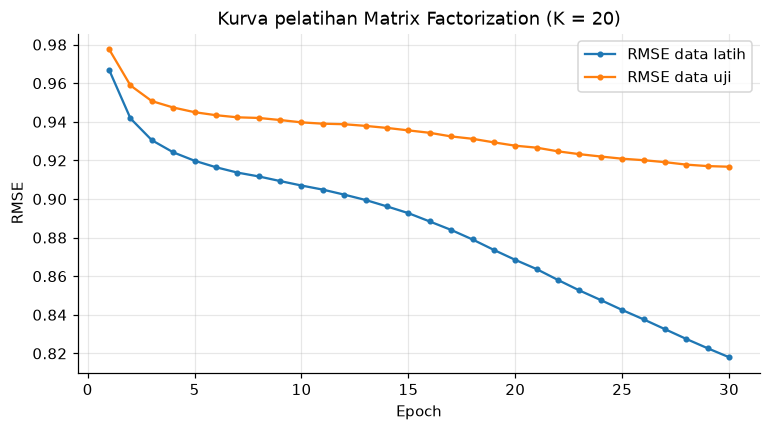

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(hist_mf["epoch"], hist_mf["train_rmse"], marker="o", ms=3, label="RMSE data latih")
plt.plot(hist_mf["epoch"], hist_mf["test_rmse"], marker="o", ms=3, label="RMSE data uji")
plt.xlabel("Epoch"); plt.ylabel("RMSE")
plt.title("Kurva pelatihan Matrix Factorization (K = 20)")
plt.legend()
plt.savefig(os.path.join(ASSET_DIR, "mf_loss.png"), bbox_inches="tight")
plt.show()

RMSE data latih terus turun, sedangkan RMSE data uji turun lalu mendatar. Regularisasi $\beta$ menjaga agar model tidak terlalu menghafal data latih (*overfitting*).

Pembanding: Matrix Factorization tanpa bias (rumus prediksi $\hat{r}_{ij} = p_i^T q_j$ seperti implementasi dasar):

In [21]:
start = time.time()
P_mf_nobias, _ = matrix_factorization(train_df, K=20, epochs=30, alpha=0.005, beta=0.2,
                                      use_bias=False, verbose=False)
print(f"Waktu komputasi: {time.time() - start:.1f} detik")
result_mf_nobias = evaluate("Matrix Factorization (tanpa bias)", P_mf_nobias)
pd.DataFrame([result_mf_nobias, result_mf]).set_index("Metode")

Waktu komputasi: 16.2 detik


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
Matrix Factorization (tanpa bias),0.7304,0.8511,0.9226,0.2128,0.9240,0.8484
Matrix Factorization,0.7238,0.8404,0.9167,0.2101,0.9221,0.8451


## 9. Contoh Rekomendasi Top-10

Rekomendasi dibuat dengan cara: prediksi rating seluruh film yang belum dirating user (di data latih), urutkan dari prediksi tertinggi, lalu ambil 10 teratas.
Agar rekomendasi tidak didominasi film yang hanya dirating 1-2 orang, kandidat dibatasi pada film yang memiliki minimal 20 rating di data latih.

In [22]:
item_count_train = (R_train > 0).sum(axis=0)

def recommend(P, user_id, n=10, min_ratings=20):
    u = user_id - 1
    candidates = np.where((R_train[u] == 0) & (item_count_train >= min_ratings))[0]
    top = candidates[np.argsort(-P[u, candidates])[:n]]
    return pd.DataFrame({"item_id": top + 1, "judul": titles.loc[top + 1].values,
                         "prediksi": P[u, top].round(3)})

USER_EXAMPLE = 1
liked = train_df[(train_df.user_id == USER_EXAMPLE)].sort_values("rating", ascending=False).head(10)
print(f"Film yang paling disukai user {USER_EXAMPLE} (data latih):")
print(liked.assign(judul=titles.loc[liked.item_id].values)[["item_id", "judul", "rating"]].to_string(index=False))

Film yang paling disukai user 1 (data latih):
 item_id                                  judul  rating
     168 Monty Python and the Holy Grail (1974)       5
     216         When Harry Met Sally... (1989)       5
      44               Dolores Claiborne (1994)       5
      87     Searching for Bobby Fischer (1993)       5
     228    Star Trek: The Wrath of Khan (1982)       5
      50                       Star Wars (1977)       5
     171                    Delicatessen (1991)       5
      42                          Clerks (1994)       5
     165                Jean de Florette (1986)       5
      45             Eat Drink Man Woman (1994)       5


In [23]:
recs = {name: recommend(P, USER_EXAMPLE) for name, P in
        [("User-Based CF", P_user), ("Item-Based CF", P_item), ("Matrix Factorization", P_mf)]}
for name, df_rec in recs.items():
    print(f"\nTop-10 rekomendasi untuk user {USER_EXAMPLE} - {name}")
    print(df_rec.to_string(index=False))


Top-10 rekomendasi untuk user 1 - User-Based CF
 item_id                                                                       judul  prediksi
     408                                                       Close Shave, A (1995)     4.915
     483                                                           Casablanca (1942)     4.692
      64                                            Shawshank Redemption, The (1994)     4.651
     100                                                                Fargo (1996)     4.639
     511                                                   Lawrence of Arabia (1962)     4.613
     474 Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1963)     4.605
     603                                                          Rear Window (1954)     4.596
     484                                                  Maltese Falcon, The (1941)     4.584
     641                                                       Paths of Glory (1957)     4.565
 

In [24]:
# Apakah rekomendasi tepat? Cek film rekomendasi yang ternyata ada di data uji user tersebut
user_test = test_df[test_df.user_id == USER_EXAMPLE].set_index("item_id")["rating"]
for name, df_rec in recs.items():
    hit = df_rec[df_rec.item_id.isin(user_test.index)]
    info = ", ".join(f"{t} (rating asli {user_test[i]})" for i, t in zip(hit.item_id, hit.judul))
    print(f"{name:22s}: {len(hit)} film ada di data uji -> {info if info else '-'}")

User-Based CF         : 2 film ada di data uji -> Shawshank Redemption, The (1994) (rating asli 5), Fargo (1996) (rating asli 5)
Item-Based CF         : 2 film ada di data uji -> Fish Called Wanda, A (1988) (rating asli 3), Return of the Jedi (1983) (rating asli 5)
Matrix Factorization  : 1 film ada di data uji -> Fargo (1996) (rating asli 5)


## 10. Perbandingan Ketiga Metode

Semua metode dievaluasi pada data uji yang sama (20% rating, `random_state = 42`).
Untuk MAE, MSE, RMSE, dan NMSE, semakin kecil semakin baik. Untuk NDCG, semakin besar semakin baik.

In [25]:
baseline_P = np.tile(user_means(R_train)[:, None], (1, n_items))
result_baseline = evaluate("Baseline (rata-rata user)", baseline_P)

main_results = pd.DataFrame([
    {**result_user, "Metode": "User-Based CF"},
    {**result_item, "Metode": "Item-Based CF"},
    {**result_mf, "Metode": "Matrix Factorization"},
]).set_index("Metode")

all_results = pd.DataFrame([result_baseline, result_user, result_item_cos, result_item,
                            result_mf_nobias, result_mf]).set_index("Metode")
all_results.to_csv(os.path.join(ASSET_DIR, "hasil_evaluasi.csv"))

def highlight(df):
    styles = pd.DataFrame("", index=df.index, columns=df.columns)
    for c in df.columns:
        best = df[c].idxmax() if c.startswith("NDCG") else df[c].idxmin()
        styles.loc[best, c] = "font-weight: bold; background-color: #dcfce7"
    return styles

print("Perbandingan utama (nilai terbaik ditebalkan):")
main_results.style.format("{:.4f}").apply(highlight, axis=None)

Perbandingan utama (nilai terbaik ditebalkan):


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
User-Based CF,0.7280,0.8718,0.9337,0.2180,0.9193,0.8387
Item-Based CF,0.7250,0.8587,0.9266,0.2147,0.9168,0.8362
Matrix Factorization,0.7238,0.8404,0.9167,0.2101,0.9221,0.8451


In [26]:
print("Perbandingan lengkap termasuk baseline dan variasi:")
all_results.style.format("{:.4f}").apply(highlight, axis=None)

Perbandingan lengkap termasuk baseline dan variasi:


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
Baseline (rata-rata user),0.8346,1.0852,1.0417,0.2713,0.8469,0.6970
User-Based CF,0.7280,0.8718,0.9337,0.2180,0.9193,0.8387
Item-Based CF (cosine),0.7642,0.9500,0.9747,0.2375,0.9115,0.8227
Item-Based CF (adjusted cosine),0.7250,0.8587,0.9266,0.2147,0.9168,0.8362
Matrix Factorization (tanpa bias),0.7304,0.8511,0.9226,0.2128,0.9240,0.8484
Matrix Factorization,0.7238,0.8404,0.9167,0.2101,0.9221,0.8451


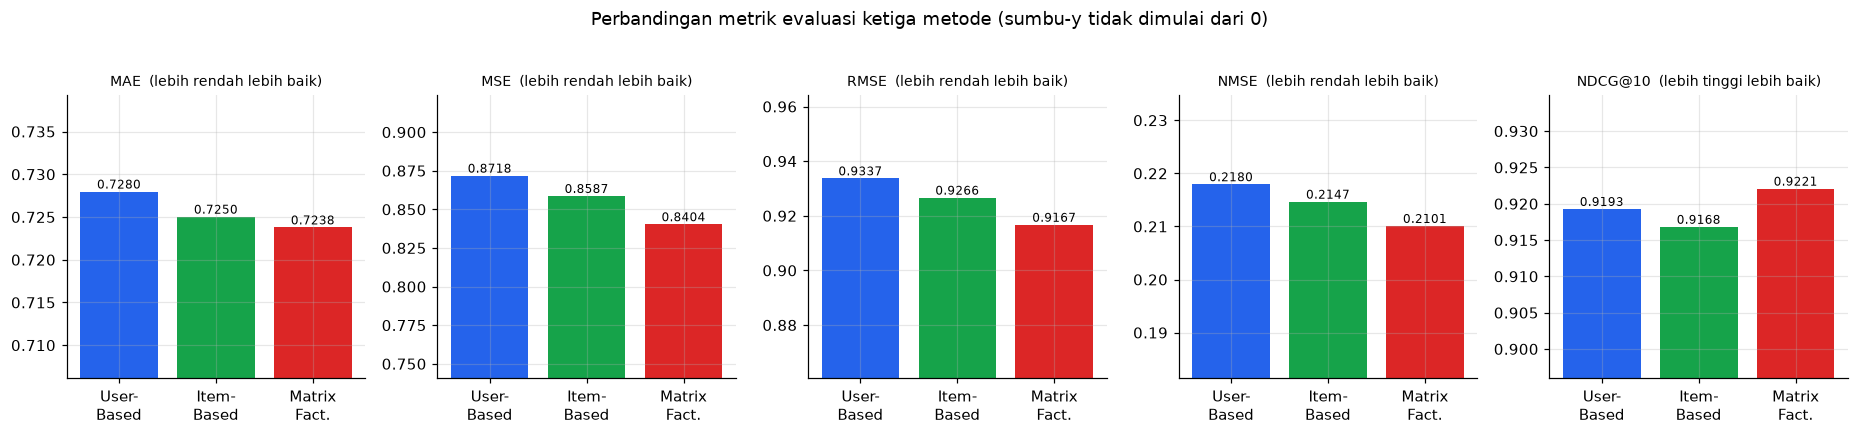

In [27]:
methods = main_results.index.tolist()
colors = [COLORS[m] for m in methods]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, metric in zip(axes, ["MAE", "MSE", "RMSE", "NMSE", "NDCG@10"]):
    vals = main_results[metric]
    bars = ax.bar(range(len(methods)), vals, color=colors)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
    lo, hi = vals.min(), vals.max()
    ax.set_ylim(lo - (hi - lo) * 3 - 0.005, hi + (hi - lo) * 1.5 + 0.005)
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(["User-\nBased", "Item-\nBased", "Matrix\nFact."])
    ax.set_title(metric + ("  (lebih tinggi lebih baik)" if metric.startswith("NDCG") else "  (lebih rendah lebih baik)"), fontsize=9)
plt.suptitle("Perbandingan metrik evaluasi ketiga metode (sumbu-y tidak dimulai dari 0)", y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "perbandingan_metrik.png"), bbox_inches="tight")
plt.show()

## 11. Eksperimen Parameter

### 11.1 Pengaruh jumlah tetangga $k$ pada User-Based dan Item-Based CF

Nilai $k$ yang terlalu besar membawa *noise* dari tetangga yang kurang mirip,
sedangkan $k$ yang terlalu kecil (di bawah 10) menurunkan kualitas prediksi (Jannach dkk., 2010). Eksperimen berikut menguji hal tersebut.
Matriks similarity cukup dihitung sekali, lalu dipakai ulang untuk setiap nilai $k$.

In [28]:
K_VALUES = [5, 10, 20, 30, 50, 100]
S_user, _, _ = user_similarity(R_train)
S_item = item_similarity(R_train, adjusted=True)

rows = []
start = time.time()
for k in K_VALUES:
    rows.append({**evaluate("User-Based CF", predict_user_based(R_train, k=k, S=S_user)), "k": k})
    rows.append({**evaluate("Item-Based CF", predict_item_based(R_train, k=k, S=S_item)), "k": k})
k_results = pd.DataFrame(rows)
print(f"Waktu eksperimen: {time.time() - start:.1f} detik")
k_results.pivot(index="k", columns="Metode", values=["MAE", "RMSE", "NDCG@10"]).round(4)

Waktu eksperimen: 155.9 detik


MAE                        RMSE                     NDCG@10  \
Metode Item-Based CF User-Based CF Item-Based CF User-Based CF Item-Based CF   
k                                                                              
5             0.7466        0.7582        0.9675        0.9752        0.9106   
10            0.7277        0.7373        0.9351        0.9479        0.9156   
20            0.7245        0.7289        0.9270        0.9358        0.9167   
30            0.7250        0.7280        0.9266        0.9337        0.9168   
50            0.7280        0.7288        0.9288        0.9340        0.9176   
100           0.7323        0.7319        0.9320        0.9364        0.9173   

                      
Metode User-Based CF  
k                     
5             0.9087  
10            0.9138  
20            0.9178  
30            0.9193  
50            0.9196  
100           0.9186

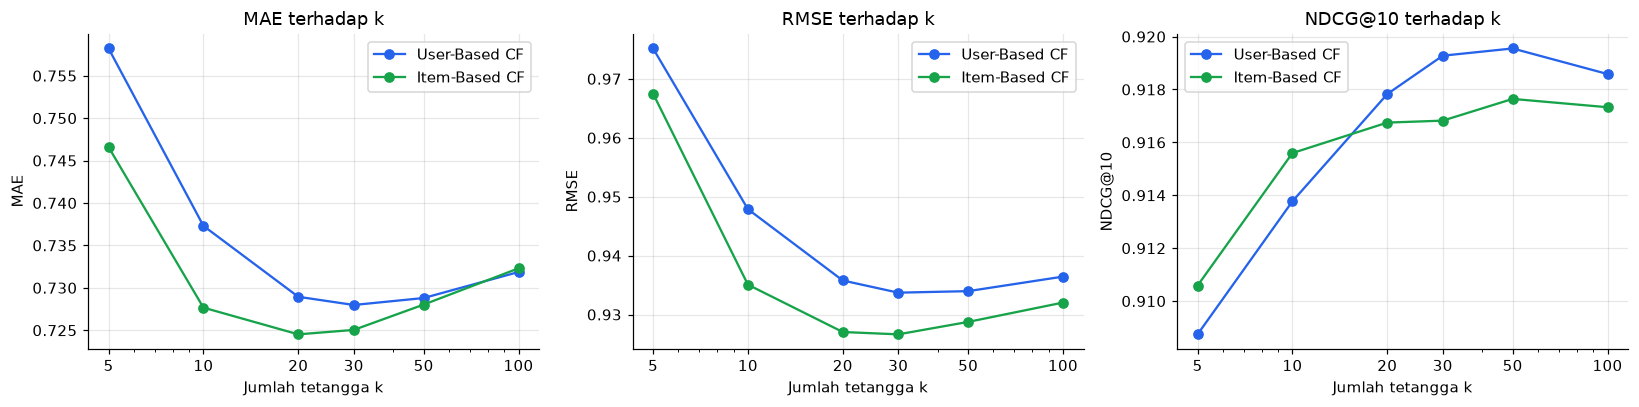

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric in zip(axes, ["MAE", "RMSE", "NDCG@10"]):
    for m in ["User-Based CF", "Item-Based CF"]:
        d = k_results[k_results.Metode == m]
        ax.plot(d["k"], d[metric], marker="o", label=m, color=COLORS[m])
    ax.set_xscale("log"); ax.set_xticks(K_VALUES); ax.set_xticklabels(K_VALUES)
    ax.set(title=f"{metric} terhadap k", xlabel="Jumlah tetangga k", ylabel=metric)
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "eksperimen_k.png"), bbox_inches="tight")
plt.show()

### 11.2 Pengaruh jumlah fitur laten $K$ pada Matrix Factorization

In [30]:
FACTORS = [5, 10, 20, 50, 100]
rows = []
start = time.time()
for K in FACTORS:
    P_k, _ = matrix_factorization(train_df, K=K, epochs=30, verbose=False)
    rows.append({**evaluate("Matrix Factorization", P_k), "K": K})
factor_results = pd.DataFrame(rows).set_index("K").drop(columns="Metode")
print(f"Waktu eksperimen: {time.time() - start:.1f} detik")
factor_results.round(4)

Waktu eksperimen: 90.8 detik


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
K,,,,,,
5,0.7289,0.8514,0.9227,0.2128,0.9199,0.8416
10,0.7254,0.8432,0.9182,0.2108,0.9198,0.8401
20,0.7238,0.8404,0.9167,0.2101,0.9221,0.8451
50,0.7214,0.8340,0.9132,0.2085,0.9221,0.8438
100,0.7195,0.8317,0.9120,0.2079,0.9221,0.8464


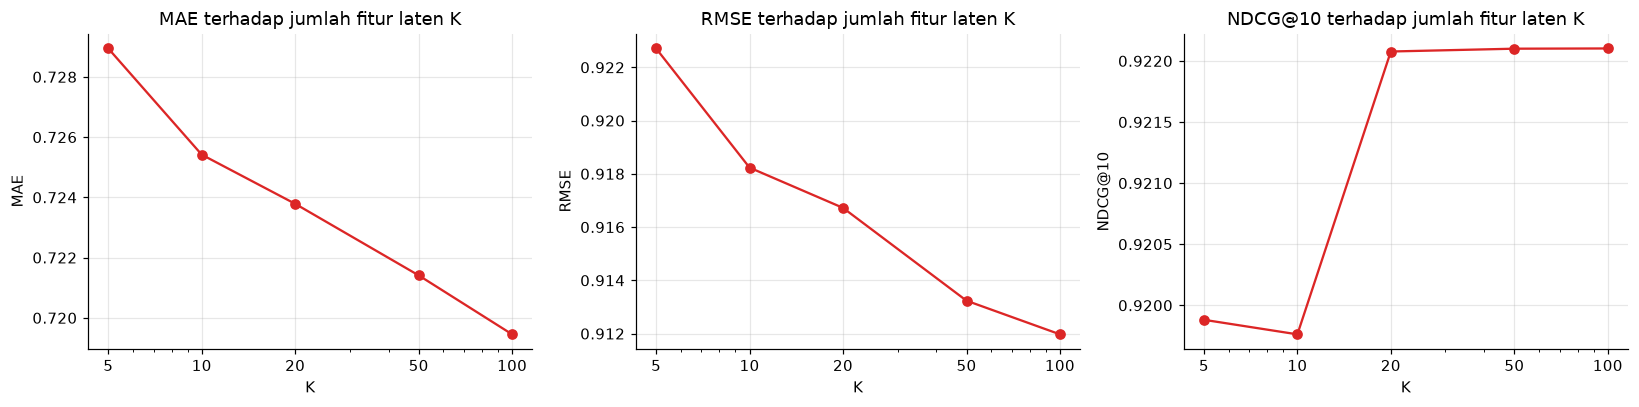

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric in zip(axes, ["MAE", "RMSE", "NDCG@10"]):
    ax.plot(factor_results.index, factor_results[metric], marker="o", color=COLORS["Matrix Factorization"])
    ax.set_xscale("log"); ax.set_xticks(FACTORS); ax.set_xticklabels(FACTORS)
    ax.set(title=f"{metric} terhadap jumlah fitur laten K", xlabel="K", ylabel=metric)
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "eksperimen_faktor.png"), bbox_inches="tight")
plt.show()

## 12. Validasi Silang 5-Fold

Evaluasi diulang beberapa kali agar hasil tidak bias oleh satu kali pembagian data acak (*N-fold cross validation*).
MovieLens 100K sudah menyediakan 5 pasang pembagian resmi (`u1.base`/`u1.test` sampai `u5.base`/`u5.test`):
data uji kelima fold saling lepas dan masing-masing berisi 20% rating.

Ketiga metode dijalankan dengan parameter yang sama seperti bagian 6 sampai 8 ($k = 30$, $K = 20$), kemudian dihitung rata-rata dan simpangan bakunya.

In [32]:
def load_split(name):
    return pd.read_csv(os.path.join(ML_DIR, name), sep="\t",
                       names=["user_id", "item_id", "rating", "timestamp"])

cv_rows = []
start = time.time()
for fold in range(1, 6):
    tr, te = load_split(f"u{fold}.base"), load_split(f"u{fold}.test")
    R_fold = build_matrix(tr)
    preds = {
        "User-Based CF": predict_user_based(R_fold, k=30),
        "Item-Based CF": predict_item_based(R_fold, k=30, adjusted=True),
        "Matrix Factorization": matrix_factorization(tr, K=20, epochs=30, verbose=False)[0],
    }
    for name, P in preds.items():
        cv_rows.append({**evaluate(name, P, test=te), "Fold": fold})
    print(f"Fold {fold} selesai ({time.time() - start:.0f} detik)")

cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(os.path.join(ASSET_DIR, "hasil_cv.csv"), index=False)

Fold 1 selesai (42 detik)


Fold 2 selesai (85 detik)


Fold 3 selesai (127 detik)


Fold 4 selesai (169 detik)


Fold 5 selesai (212 detik)


In [33]:
metric_cols = ["MAE", "MSE", "RMSE", "NMSE", "NDCG@10", "NDCG@10 (biner)"]
order = ["User-Based CF", "Item-Based CF", "Matrix Factorization"]
cv_mean = cv_results.groupby("Metode")[metric_cols].mean().loc[order]
cv_std = cv_results.groupby("Metode")[metric_cols].std().loc[order]
cv_summary = cv_mean.round(4).astype(str) + " ± " + cv_std.round(4).astype(str)
print("Rata-rata ± simpangan baku dari 5 fold:")
cv_summary

Rata-rata ± simpangan baku dari 5 fold:


,MAE,MSE,RMSE,NMSE,NDCG@10,NDCG@10 (biner)
Metode,,,,,,
User-Based CF,0.731 ± 0.0051,0.8782 ± 0.0117,0.9371 ± 0.0062,0.2196 ± 0.0029,0.9162 ± 0.0127,0.8467 ± 0.0105
Item-Based CF,0.7294 ± 0.0083,0.8724 ± 0.0191,0.934 ± 0.0102,0.2181 ± 0.0048,0.9132 ± 0.0121,0.8424 ± 0.0079
Matrix Factorization,0.7259 ± 0.0057,0.8438 ± 0.0127,0.9186 ± 0.0069,0.211 ± 0.0032,0.9187 ± 0.0121,0.8521 ± 0.0091


In [34]:
print("Hasil per fold (RMSE):")
cv_results.pivot(index="Fold", columns="Metode", values="RMSE")[order].round(4)

Hasil per fold (RMSE):


Metode,User-Based CF,Item-Based CF,Matrix Factorization
Fold,,,
1,0.9474,0.9515,0.9303
2,0.9381,0.9306,0.9188
3,0.9345,0.9268,0.9140
4,0.9319,0.9274,0.9138
5,0.9336,0.9337,0.9159


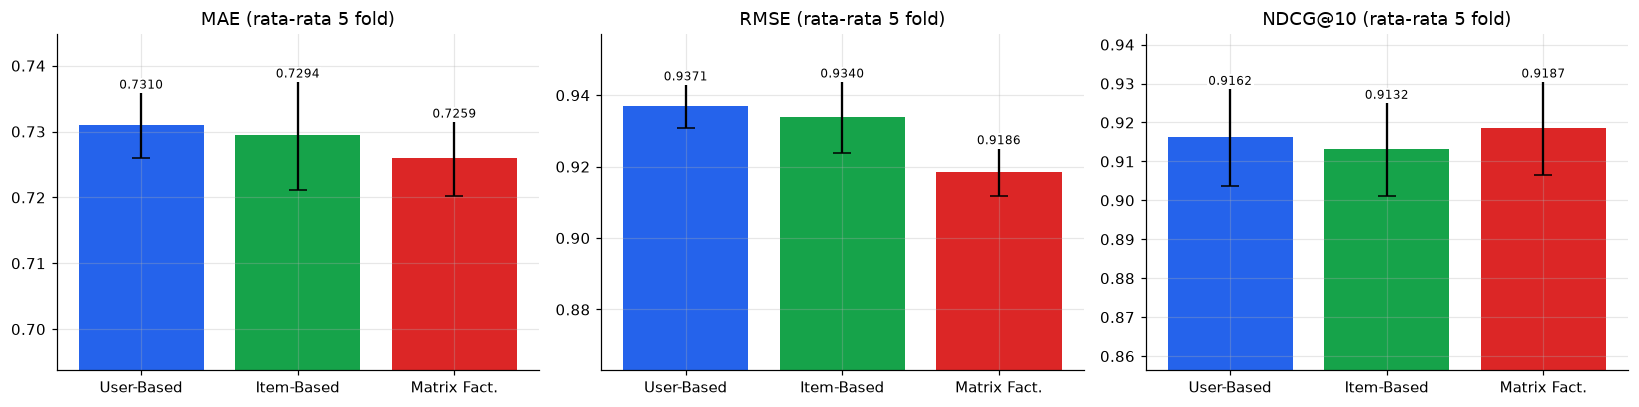

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric in zip(axes, ["MAE", "RMSE", "NDCG@10"]):
    ax.bar(range(3), cv_mean[metric], yerr=cv_std[metric], capsize=6, color=[COLORS[m] for m in order])
    for x, (v, s) in enumerate(zip(cv_mean[metric], cv_std[metric])):
        ax.text(x, v + s, f"{v:.4f}", ha="center", va="bottom", fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    lo = (cv_mean[metric] - cv_std[metric]).min()
    hi = (cv_mean[metric] + cv_std[metric]).max()
    ax.set_ylim(lo - (hi - lo) * 1.5, hi + (hi - lo) * 0.4)
    ax.set_xticks(range(3)); ax.set_xticklabels(["User-Based", "Item-Based", "Matrix Fact."])
    ax.set_title(f"{metric} (rata-rata 5 fold)")
plt.tight_layout()
plt.savefig(os.path.join(ASSET_DIR, "cv_perbandingan.png"), bbox_inches="tight")
plt.show()

## 13. Analisis dan Kesimpulan

### 13.1 Ringkasan hasil

Data uji utama (split 80:20, `random_state = 42`):

| Metode | MAE | MSE | RMSE | NMSE | NDCG@10 | NDCG@10 (biner) |
|---|---|---|---|---|---|---|
| Baseline (rata-rata user) | 0,8346 | 1,0852 | 1,0417 | 0,2713 | 0,8469 | 0,6970 |
| User-Based CF (k = 30) | 0,7280 | 0,8718 | 0,9337 | 0,2180 | 0,9193 | 0,8387 |
| Item-Based CF (adjusted cosine, k = 30) | 0,7250 | 0,8587 | 0,9266 | 0,2147 | 0,9168 | 0,8362 |
| Matrix Factorization (K = 20) | 0,7238 | 0,8404 | 0,9167 | 0,2101 | 0,9221 | 0,8451 |

Validasi silang 5-fold (rata-rata ± simpangan baku):

| Metode | MAE | RMSE | NMSE | NDCG@10 | NDCG@10 (biner) |
|---|---|---|---|---|---|
| User-Based CF | 0,7310 ± 0,0051 | 0,9371 ± 0,0062 | 0,2196 ± 0,0029 | 0,9162 ± 0,0127 | 0,8467 ± 0,0105 |
| Item-Based CF | 0,7294 ± 0,0083 | 0,9340 ± 0,0102 | 0,2181 ± 0,0048 | 0,9132 ± 0,0121 | 0,8424 ± 0,0079 |
| Matrix Factorization | 0,7259 ± 0,0057 | 0,9186 ± 0,0069 | 0,2110 ± 0,0032 | 0,9187 ± 0,0121 | 0,8521 ± 0,0091 |

### 13.2 Analisis

#### Perbandingan dengan baseline

Baseline yang selalu menebak rata-rata rating user menghasilkan RMSE 1,0417. Ketiga metode collaborative filtering menurunkan RMSE menjadi sekitar 0,92 sampai 0,93
(perbaikan sekitar 10 sampai 12%) dan menaikkan NDCG@10 biner dari 0,697 menjadi sekitar 0,84 sampai 0,85.
Artinya, informasi dari user lain dan item lain (*wisdom of the crowd*) benar-benar membantu prediksi.

#### Keunggulan Matrix Factorization

Matrix Factorization unggul di semua metrik error (MAE, MSE, RMSE, NMSE), baik pada split utama maupun rata-rata 5-fold, dan juga memiliki NDCG tertinggi.
Selisih RMSE MF dengan kedua metode CF (sekitar 0,015) lebih besar daripada simpangan baku antarfold (sekitar 0,006 sampai 0,010), dan MF menang di kelima fold,
sehingga keunggulannya konsisten, bukan kebetulan pembagian data. MF dapat menemukan fitur laten yang mendasari interaksi user dan item (Koren dkk., 2009).
Dua user yang tidak pernah merating film yang sama tetap dapat terhubung melalui fitur laten, sehingga MF lebih tahan terhadap *sparsity* (93,7% sel kosong).

#### User-Based CF dan Item-Based CF

Pada split utama Item-Based CF sedikit lebih baik (RMSE 0,9266 dibanding 0,9337). Pada validasi silang selisihnya hanya 0,003, lebih kecil dari simpangan bakunya,
sehingga keduanya dapat dianggap setara dalam akurasi. Namun Item-Based CF memiliki keunggulan praktis: matriks kemiripan item dapat dihitung terlebih dahulu (*offline*)
dan lebih stabil karena satu film dirating oleh banyak user. Pada eksperimen ini Item-Based CF juga lebih cepat (sekitar 3 detik dibanding 22 detik untuk User-Based CF).

#### Cosine dan adjusted cosine

Pada Item-Based CF, RMSE turun dari 0,9747 (cosine) menjadi 0,9266 (adjusted cosine). Cosine biasa mengabaikan perbedaan kebiasaan merating antar user
(ada user yang selalu memberi rating 4 sampai 5, ada yang jarang memberi rating tinggi). Adjusted cosine mengurangi rata-rata user terlebih dahulu sehingga yang dibandingkan adalah
apakah user lebih suka atau kurang suka dari biasanya. Contoh Alice di bagian 7.1 memperlihatkan efek yang sama: dengan cosine biasa semua item tampak mirip (0,62 sampai 0,81).

#### Pengaruh jumlah tetangga k

Dengan k = 5, RMSE paling buruk (0,975 untuk User-Based dan 0,968 untuk Item-Based) karena prediksi hanya bergantung pada sedikit tetangga.
Error terkecil dicapai pada k = 20 sampai 30, lalu naik lagi pada k = 100 karena tetangga yang kurang mirip menambah *noise*.
Hasil ini sejalan dengan rentang 20 sampai 50 tetangga yang umum digunakan untuk dataset MovieLens (Jannach dkk., 2010).

#### Pengaruh jumlah fitur laten K

RMSE MF turun perlahan dari 0,9227 (K = 5) ke 0,9120 (K = 100). Penambahan fitur laten memberi model kapasitas lebih untuk menangkap selera user,
tetapi peningkatannya semakin kecil (*diminishing returns*). Regularisasi $\beta$ mencegah model dengan K besar menjadi *overfitting*.
Kurva pelatihan juga menunjukkan RMSE uji masih sedikit turun pada epoch 30, sehingga penambahan epoch atau *tuning* $\alpha$ dan $\beta$ masih berpotensi memperbaiki hasil.

#### Metrik error dan NDCG

MAE, MSE, RMSE, dan NMSE mengukur ketepatan nilai rating, sedangkan NDCG mengukur ketepatan urutan item.
Keduanya tidak selalu sejalan: MF tanpa bias memiliki RMSE lebih buruk (0,9226) daripada MF dengan bias (0,9167), tetapi NDCG-nya sedikit lebih tinggi (0,9240 dibanding 0,9221).
Bias user menggeser semua prediksi seorang user secara merata sehingga memperbaiki nilai rating, tetapi tidak mengubah urutan item untuk user tersebut.

Nilai NDCG graded terlihat tinggi (di atas 0,91, bahkan baseline 0,847) karena NDCG dihitung dengan mengurutkan item-item yang sudah dirating user di data uji
dan semua rating bernilai positif (1 sampai 5). NDCG biner (relevan jika rating $\geq 4$) lebih tegas membedakan metode dari baseline (0,697 menjadi sekitar 0,84 sampai 0,85).

#### Sparsity dan cold-start

Nilai similarity tetangga terdekat user 1 hanya sekitar 0,17 sampai 0,19, karena dua user rata-rata hanya berbagi sedikit film.
Selain itu, 29 film di data uji tidak pernah muncul di data latih (*cold-start item*), sehingga ketiga metode hanya dapat memakai rata-rata user sebagai prediksi.
Masalah ini dapat diatasi dengan pendekatan hybrid, misalnya menggabungkan *content-based filtering* berdasarkan genre film.

#### Kelebihan dan kekurangan ketiga metode

| Aspek | User-Based CF | Item-Based CF | Matrix Factorization |
|---|---|---|---|
| Akurasi (RMSE 5-fold) | 0,9371 | 0,9340 | 0,9186 |
| Kemudahan dijelaskan | Mudah ("user yang mirip dengan Anda menyukai...") | Mudah ("karena Anda menyukai film X...") | Sulit, fitur laten tidak bermakna langsung |
| Skalabilitas | Kurang, similarity antar user O(m²) | Lebih baik, similarity item dapat dihitung terlebih dahulu | Baik saat prediksi, tetapi perlu pelatihan |
| Ketahanan terhadap sparsity | Rendah | Sedang | Tinggi |
| Parameter utama | k tetangga | k tetangga, jenis similarity | K, $\alpha$, $\beta$, epoch |

### 13.3 Kesimpulan

1. Ketiga metode berhasil memprediksi rating dan membuat rekomendasi Top-10 dari riwayat rating user MovieLens 100K, dan semuanya jauh lebih akurat daripada baseline rata-rata user.
2. Matrix Factorization memberikan hasil terbaik di semua metrik: RMSE 0,9167 dan NDCG@10 0,9221 pada data uji utama, serta RMSE 0,9186 ± 0,0069 pada validasi silang 5-fold.
3. User-Based CF dan Item-Based CF memiliki akurasi yang hampir sama. Item-Based CF dengan adjusted cosine lebih praktis karena lebih cepat dan matriks similarity-nya dapat dihitung terlebih dahulu.
4. Pemilihan parameter berpengaruh: adjusted cosine lebih baik daripada cosine biasa, jumlah tetangga terbaik berada di kisaran 20 sampai 30, dan penambahan fitur laten pada MF memberi peningkatan kecil.
5. Metrik error dan metrik ranking mengukur hal berbeda, sehingga evaluasi sistem rekomendasi sebaiknya memakai keduanya.

### Daftar Pustaka

1. Baizal, Z. K. A. dan Wibowo, A. T. *Sistem Rekomendasi*. Bandung: Telkom University.
2. Harper, F. M. dan Konstan, J. A. (2015). The MovieLens Datasets: History and Context. *ACM Transactions on Interactive Intelligent Systems*, 5(4), 1-19.
3. Jannach, D., Zanker, M., Felfernig, A., dan Friedrich, G. (2010). *Recommender Systems: An Introduction*. Cambridge: Cambridge University Press.
4. Järvelin, K. dan Kekäläinen, J. (2002). Cumulated Gain-Based Evaluation of IR Techniques. *ACM Transactions on Information Systems*, 20(4), 422-446.
5. Koren, Y., Bell, R., dan Volinsky, C. (2009). Matrix Factorization Techniques for Recommender Systems. *Computer*, 42(8), 30-37.
6. Sarwar, B., Karypis, G., Konstan, J., dan Riedl, J. (2001). Item-Based Collaborative Filtering Recommendation Algorithms. *Proceedings of the 10th International Conference on World Wide Web*, 285-295.
7. Yeung, A. A. (2010). *Matrix Factorization: A Simple Tutorial and Implementation in Python*. quuxlabs.com.